# 02 · Exploratory data analysis

**Financial Fraud Detection Using Machine Learning and Deep Learning**

This notebook explores the original PaySim data before modelling. It checks data quality, quantifies class imbalance, and examines transaction types, amounts and simulated time. It does not train a model or select a decision threshold.

**Dataset:** [PaySim on Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1) · **Unit of analysis:** one simulated transaction · **Target:** `isFraud` (1 = fraud, 0 = legitimate).

**How to run:** select the project Python kernel and choose **Run All**. The CSV must be at `data/raw/PS_20174392719_1491204439457_log.csv`. Packages used: `pandas`, `numpy`, `matplotlib` and `ipykernel`. The full file is read in chunks to limit memory use.

**Interpretation:** PaySim is synthetic. These are descriptions of this dataset, not estimates of fraud rates in real payment systems. This exploration uses the entire dataset; any later modelling evaluation needs a separate split and must avoid choosing features or thresholds based on test results.

**Environment note:** This run used the project’s Python 3.15 environment. The existing `requirements.txt` describes a separate Python 3.10 setup; it must be reconciled before the full project is considered reproducible.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": 0.18, "axes.axisbelow": True})
BLUE, RED, GREY = "#2563a6", "#d95b43", "#64748b"
SEED, CHUNK_SIZE, LEGIT_SAMPLE_FRACTION = 42, 500_000, 0.02
cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "data" / "README.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from inside the project folder.")
DATA_PATH = ROOT / "data" / "raw" / "PS_20174392719_1491204439457_log.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. See data/README.md.")
print("Dataset:", DATA_PATH.relative_to(ROOT).as_posix())
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__,
      "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)

Dataset: data/raw/PS_20174392719_1491204439457_log.csv
Python: 3.15.2 | pandas: 3.1.1 | numpy: 2.5.4 | matplotlib: 3.11.2


## 1. Load and audit the data

Counts, missing values, transaction-type summaries and time summaries below use **every row**. For amount-distribution plots and quantiles, the notebook keeps all fraud cases and a reproducible 2% sample of legitimate transactions, sampled independently within each chunk. Sample-based results are labeled. The input file is not changed.

In [2]:
required = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig",
            "nameDest", "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
header = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
missing_columns = sorted(set(required) - set(header))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

class_counts = pd.Series(dtype="int64")
type_counts = pd.DataFrame()
day_counts = pd.DataFrame()
null_counts = pd.Series(0, index=header, dtype="int64")
flag_counts = pd.DataFrame()
samples = []
total_rows = 0
for i, chunk in enumerate(pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE)):
    total_rows += len(chunk)
    null_counts = null_counts.add(chunk.isna().sum(), fill_value=0).astype("int64")
    class_counts = class_counts.add(chunk["isFraud"].value_counts(dropna=False), fill_value=0)
    grouped_type = chunk.groupby(["type", "isFraud"], dropna=False, observed=True).size().unstack(fill_value=0)
    type_counts = type_counts.add(grouped_type, fill_value=0)
    # PaySim defines a simulation step as one hour. Group in 24-step blocks starting at step 1.
    day = ((chunk["step"] - 1) // 24 + 1).rename("simulation_day")
    grouped_day = chunk.groupby([day, "isFraud"], dropna=False, observed=True).size().unstack(fill_value=0)
    day_counts = day_counts.add(grouped_day, fill_value=0)
    grouped_flag = chunk.groupby(["isFlaggedFraud", "isFraud"], dropna=False, observed=True).size().unstack(fill_value=0)
    flag_counts = flag_counts.add(grouped_flag, fill_value=0)
    keep = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
    fraud = chunk.loc[chunk["isFraud"].eq(1), keep]
    legitimate = chunk.loc[chunk["isFraud"].eq(0), keep].sample(frac=LEGIT_SAMPLE_FRACTION, random_state=SEED + i)
    samples.append(pd.concat([fraud, legitimate], ignore_index=True))

class_counts = class_counts.astype("int64").sort_index()
type_counts = type_counts.reindex(columns=[0, 1], fill_value=0).fillna(0).astype("int64")
day_counts = day_counts.reindex(columns=[0, 1], fill_value=0).fillna(0).astype("int64").sort_index()
flag_counts = flag_counts.reindex(columns=[0, 1], fill_value=0).fillna(0).astype("int64").sort_index()
sample = pd.concat(samples, ignore_index=True)
del samples, chunk
if set(class_counts.index) != {0, 1}:
    raise ValueError(f"Unexpected or missing target labels: {class_counts.index.tolist()}")
print(f"Rows: {total_rows:,} | Columns: {len(header)} | CSV size: {DATA_PATH.stat().st_size / 1e6:,.1f} MB")
print(f"Amount-analysis sample: {len(sample):,} rows; all fraud cases + ~2% of legitimate rows")
print(f"Sampling seed: {SEED}; chunk size: {CHUNK_SIZE:,}")
print("Columns:", ", ".join(header))

Rows: 6,362,620 | Columns: 11 | CSV size: 493.5 MB
Amount-analysis sample: 135,298 rows; all fraud cases + ~2% of legitimate rows
Sampling seed: 42; chunk size: 500,000
Columns: step, type, amount, nameOrig, oldbalanceOrg, newbalanceOrig, nameDest, oldbalanceDest, newbalanceDest, isFraud, isFlaggedFraud


In [3]:
quality = pd.DataFrame({"missing_values": null_counts, "missing_percent": null_counts / total_rows * 100})
quality.index.name = "column"
display(quality)
print(f"Total missing cells: {int(null_counts.sum()):,}")

,missing_values,missing_percent
column,,
step,0,0.0000
type,0,0.0000
amount,0,0.0000
nameOrig,0,0.0000
oldbalanceOrg,0,0.0000
newbalanceOrig,0,0.0000
nameDest,0,0.0000
oldbalanceDest,0,0.0000
newbalanceDest,0,0.0000


Total missing cells: 0


## 2. Class imbalance

A high overall accuracy can hide poor fraud detection when most transactions are legitimate. The table and plot use the full dataset. The plot has a **logarithmic count axis** because the class sizes differ greatly.

,transactions,percent
Legitimate (0),6354407,99.8709
Fraud (1),8213,0.1291


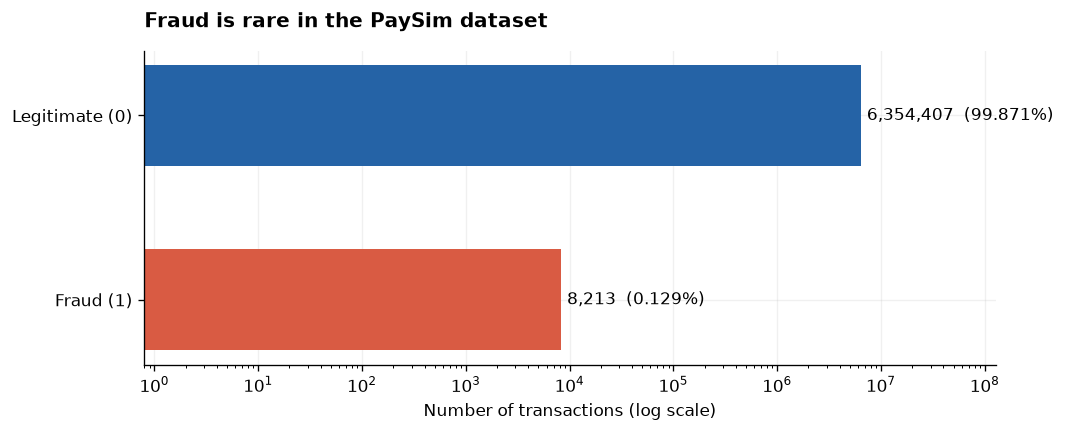

In [4]:
class_table = pd.DataFrame({"transactions": class_counts, "percent": class_counts / total_rows * 100})
class_table.index = ["Legitimate (0)", "Fraud (1)"]
display(class_table)
fig, ax = plt.subplots(figsize=(9, 3.7))
labels = class_table.index.tolist()
values = class_table["transactions"].to_numpy()
ax.barh(labels, values, color=[BLUE, RED], height=0.55)
ax.set_xscale("log")
ax.set_xlabel("Number of transactions (log scale)")
ax.set_title("Fraud is rare in the PaySim dataset", loc="left", pad=14)
ax.invert_yaxis()
for j, (value, pct) in enumerate(zip(values, class_table["percent"])):
    ax.text(value * 1.15, j, f"{value:,}  ({pct:.3f}%)", va="center", fontsize=10)
ax.set_xlim(0.8, max(values) * 20)
fig.tight_layout()
plt.show()

## 3. Transaction types

The table uses all transactions. Fraud rate is calculated **within each transaction type**; it should not be confused with that type's share of all fraud.

isFraud,legitimate,fraud,total,fraud_rate_percent,share_of_all_fraud_percent
transaction_type,,,,,
CASH_OUT,2233384,4116,2237500,0.1840,50.1157
PAYMENT,2151495,0,2151495,0.0000,0.0000
CASH_IN,1399284,0,1399284,0.0000,0.0000
TRANSFER,528812,4097,532909,0.7688,49.8843
DEBIT,41432,0,41432,0.0000,0.0000


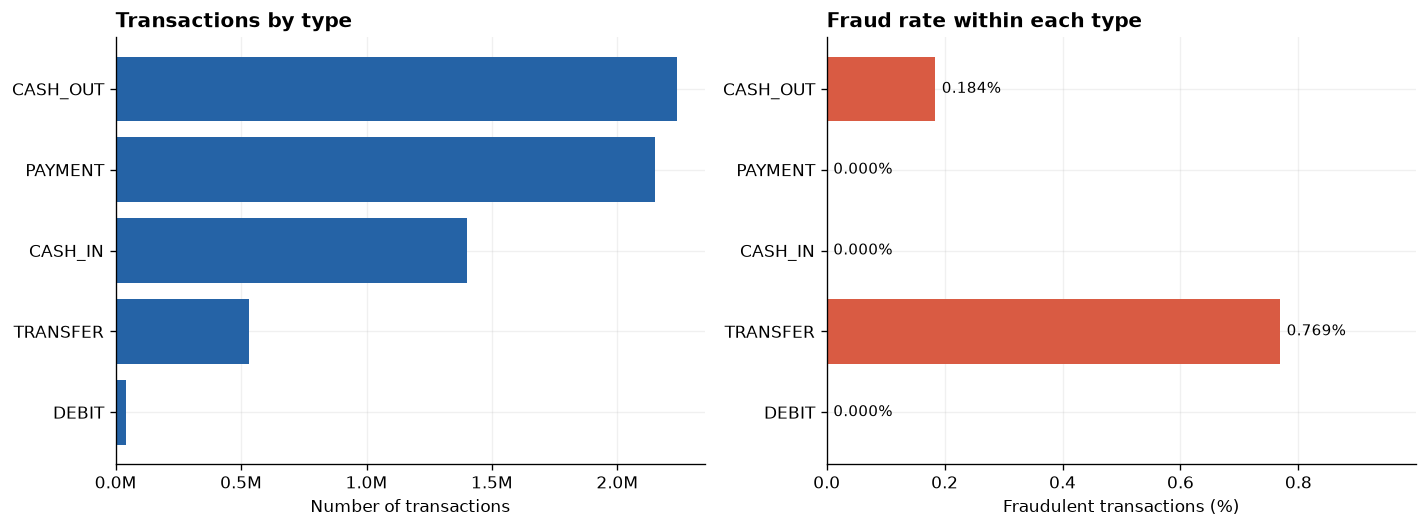

In [5]:
type_summary = type_counts.rename(columns={0: "legitimate", 1: "fraud"}).copy()
type_summary["total"] = type_summary["legitimate"] + type_summary["fraud"]
type_summary["fraud_rate_percent"] = type_summary["fraud"] / type_summary["total"].replace(0, np.nan) * 100
type_summary["share_of_all_fraud_percent"] = type_summary["fraud"] / class_counts.loc[1] * 100
type_summary = type_summary.sort_values("total", ascending=False)
type_summary.index.name = "transaction_type"
display(type_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(type_summary.index, type_summary["total"], color=BLUE)
axes[0].invert_yaxis()
axes[0].set_title("Transactions by type", loc="left")
axes[0].set_xlabel("Number of transactions")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
axes[1].barh(type_summary.index, type_summary["fraud_rate_percent"], color=RED)
axes[1].invert_yaxis()
axes[1].set_title("Fraud rate within each type", loc="left")
axes[1].set_xlabel("Fraudulent transactions (%)")
for j, v in enumerate(type_summary["fraud_rate_percent"]):
    axes[1].annotate(f"{v:.3f}%", (v, j), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
axes[1].set_xlim(0, max(type_summary["fraud_rate_percent"].max() * 1.3, .01))
fig.tight_layout()
plt.show()

## 4. Transaction amounts

These summaries use **all fraudulent transactions and a 2% sample of legitimate transactions**. The chart compares the shape of each group's amount distribution: bars are normalized within each group, so they do not represent the dataset's class prevalence. The horizontal axis uses `log10(1 + amount)` to display a wide range of positive amounts.

,sample_size,minimum,median,mean,p90,p99,maximum
Legitimate — sample,127085,0.4100,"73,723.9500","178,155.8553","363,064.1620","1,601,433.1560","51,141,938.1700"
Fraud — all,8213,0.0000,"441,423.4400","1,467,967.2991","4,521,723.5120","10,000,000.0000","10,000,000.0000"


Negative amounts in the analysis sample: 0


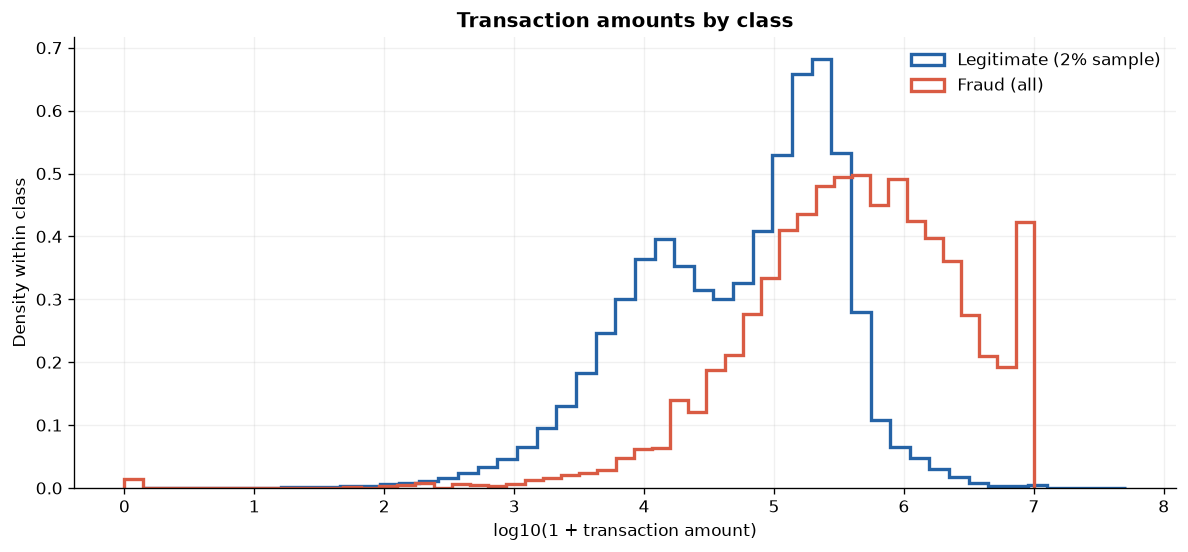

In [6]:
amount_summary = sample.groupby("isFraud")["amount"].agg(sample_size="count", minimum="min", median="median", mean="mean", p90=lambda s: s.quantile(.90), p99=lambda s: s.quantile(.99), maximum="max")
amount_summary.index = ["Legitimate — sample", "Fraud — all"]
display(amount_summary)
negatives = int((sample["amount"] < 0).sum())
print(f"Negative amounts in the analysis sample: {negatives:,}")
if negatives:
    raise ValueError("Negative amounts found; inspect them before using the log transform.")
fig, ax = plt.subplots(figsize=(10, 4.7))
for label, name, color in [(0, "Legitimate (2% sample)", BLUE), (1, "Fraud (all)", RED)]:
    values = np.log10(1 + sample.loc[sample["isFraud"].eq(label), "amount"].to_numpy())
    ax.hist(values, bins=50, density=True, histtype="step", linewidth=2, label=name, color=color)
ax.set(title="Transaction amounts by class", xlabel="log10(1 + transaction amount)", ylabel="Density within class")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. Fraud over simulated time

The next plots use every transaction. A day is a block of 24 PaySim steps, starting at step 1. Changes may reflect the simulator or changing transaction volume; this chart alone does not establish a real-world trend.

isFraud,legitimate,fraud,total,fraud_rate_percent
simulation_day,,,,
1,573984,271,574255,0.0472
2,454929,309,455238,0.0679
3,760,310,1070,28.9720
4,27978,262,28240,0.9278
5,9537,252,9789,2.5743
6,440777,228,441005,0.0517
7,420311,272,420583,0.0647
8,449359,278,449637,0.0618
9,417664,255,417919,0.0610


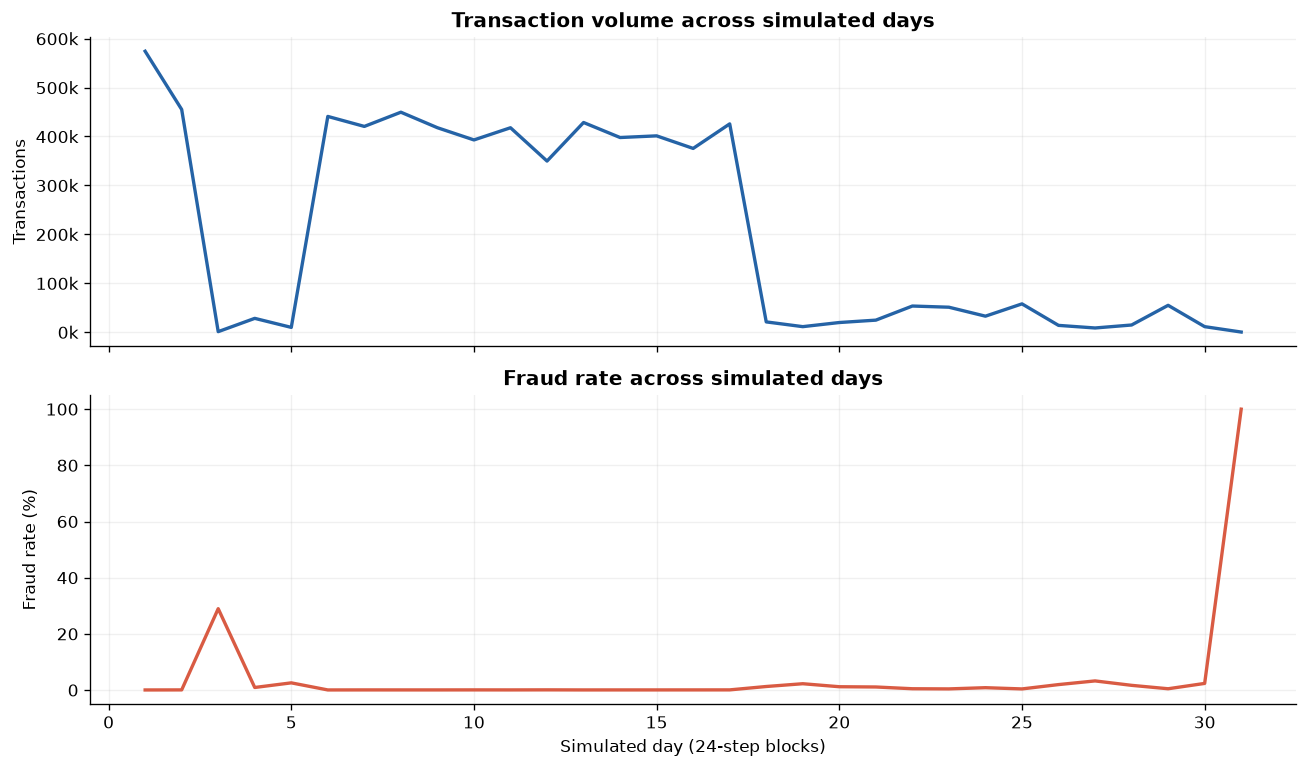

In [7]:
day_summary = day_counts.rename(columns={0: "legitimate", 1: "fraud"}).copy()
day_summary["total"] = day_summary["legitimate"] + day_summary["fraud"]
day_summary["fraud_rate_percent"] = day_summary["fraud"] / day_summary["total"].replace(0, np.nan) * 100
display(day_summary)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(day_summary.index, day_summary["total"], color=BLUE, linewidth=2)
axes[0].set(title="Transaction volume across simulated days", ylabel="Transactions")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}k"))
axes[1].plot(day_summary.index, day_summary["fraud_rate_percent"], color=RED, linewidth=2)
axes[1].set(title="Fraud rate across simulated days", xlabel="Simulated day (24-step blocks)", ylabel="Fraud rate (%)")
fig.tight_layout()
plt.show()

## 6. Modelling cautions from the data

`isFlaggedFraud` is an existing simulator flag, not the ground-truth label. Its relationship to fraud is shown descriptively below. For a fair model comparison, we must decide in advance whether it is a feature or a separate rule baseline; a flag computed using information unavailable at prediction time must not be used as an input.

Similarly, account identifiers and post-transaction balances require care: decide when predictions are made and whether a feature exists at that moment. Dataset-specific patterns or information from after a transaction can produce misleadingly strong results. The full-dataset exploration above is descriptive; select and evaluate the final modelling pipeline using training/validation data and a held-out test set.

In [8]:
flag_table = flag_counts.rename(columns={0: "legitimate", 1: "fraud"}).copy()
flag_table["total"] = flag_table.sum(axis=1)
flag_table.index.name = "isFlaggedFraud"
display(flag_table)
print("Check future model inputs for identifiers, existing flags, post-transaction information and other leakage risks.")

isFraud,legitimate,fraud,total
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16


Check future model inputs for identifiers, existing flags, post-transaction information and other leakage risks.


## 7. Reproducibility and next steps

The SHA-256 fingerprint below identifies the exact local file analyzed. The legitimate-amount sample depends on the stated seed, fraction, chunk size, input row order and pandas version. Overall counts, missingness, transaction-type tables and time tables use the full file.

**Next:** establish the prediction point and a train/validation/test strategy; fit preprocessing on training data only; then implement the logistic-regression baseline and the other models described in the project proposal. Do not treat the descriptive plots above as model performance.

In [9]:
sha256 = hashlib.sha256()
with DATA_PATH.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        sha256.update(block)
print("SHA-256:", sha256.hexdigest())
print("Dataset source: https://www.kaggle.com/datasets/ealaxi/paysim1")
print(f"Rows: {total_rows:,}; fraud: {int(class_counts.loc[1]):,}; legitimate: {int(class_counts.loc[0]):,}")

SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b
Dataset source: https://www.kaggle.com/datasets/ealaxi/paysim1
Rows: 6,362,620; fraud: 8,213; legitimate: 6,354,407
